# Commuter Ridership & Station Congestion Analysis 

In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [2]:
public_transport_utilisation_ridership_df = pd.read_csv("public_transport_utilisation_avg_public_transport_ridership.csv")
public_transport_utilisation_ridership_df.head()

,year,mode,ridership
0,1995,MRT,740000
1,1995,LRT,0
2,1995,Bus,3009000
3,1996,MRT,850000
4,1996,LRT,0


In [10]:
public_transport_ops_ridership_annual_df = pd.read_csv("public_transport_operation_ridership_annual.csv")
public_transport_ops_ridership_annual_df

,DataSeries,2025,2024,2023,2022,2021,2020,2019,2018,2017,...,1999,1998,1997,1996,1995,1994,1993,1992,1991,1990
0,Rail Length,271.3,271.3,258.5,258.5,245.3,232.3,228.1,228.1,228.1,...,90.8,83,83,83,67,67,67,67,67,67
1,Mass Rapid Transit (MRT),242.5,242.5,229.7,229.7,216.5,203.5,199.3,199.3,199.3,...,83,83,83,83,67,67,67,67,67,67
2,Light Rail Transit (LRT),28.8,28.8,28.8,28.8,28.8,28.8,28.8,28.8,28.8,...,7.8,na,na,na,na,na,na,na,na,na
3,MRT km Operated,47623,45609.0,43579.0,41785.0,40613.0,39362.0,40883.0,40676,36278,...,na,na,na,na,na,na,na,na,na,na
4,LRT km Operated,7717,7257.0,7104.0,7037.0,7019.0,6799.0,7566.0,7302,7233,...,na,na,na,na,na,na,na,na,na,na
5,Average Daily Ridership - MRT,3490,3412.0,3243.0,2745.0,2100.0,2023.0,3384.0,3302,3122,...,986,946,911,850,740,na,na,na,na,na
6,Average Daily Ridership - LRT,209,210.0,202.0,184.0,151.0,139.0,208.0,199,190,...,27,0,0,0,0,na,na,na,na,na
7,Average Daily Ridership - Public Bus,3841,3837.0,3747.0,3461.0,3008.0,2878.0,4099.0,4037,3952,...,3213,3121,3116,3118,3009,na,na,na,na,na
8,Average Daily Trip - Point-To-Point (P2P) Tran...,626,618.0,606.0,582.0,553.0,517.0,772.0,755,na,...,na,na,na,na,na,na,na,na,na,na
9,Total Ridership By MRT And LRT,na,1326000.0,1258000.0,1069000.0,821000.0,791000.0,1311000.0,1278000,1209000,...,na,na,na,na,na,na,na,na,na,na


#### BQ1: How has the daily public transport ridership across MRT, LRT, and buses evolved year-by-year over the past decade?

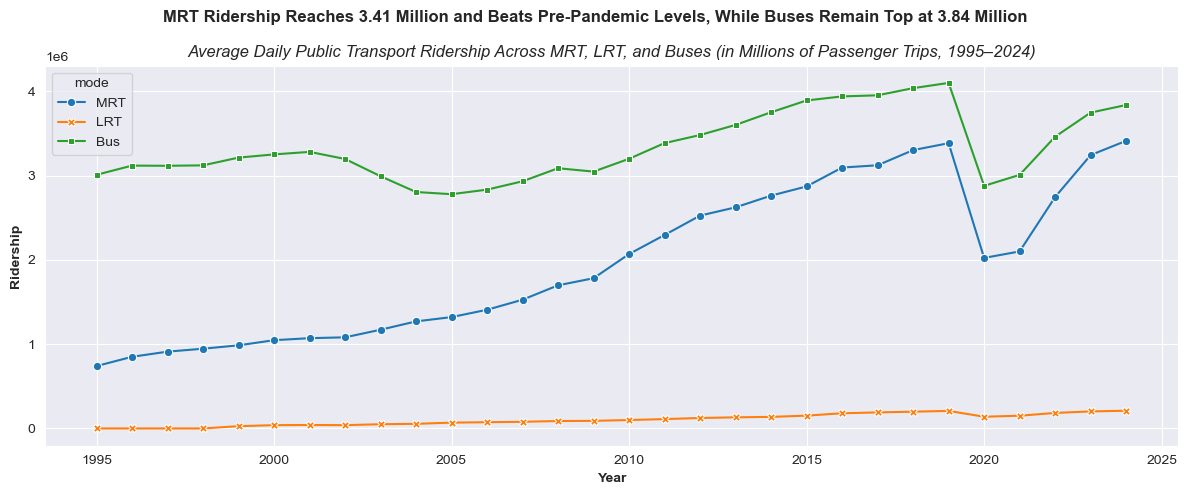

In [4]:
sns.set_style("darkgrid")
plt.figure(figsize = (12, 5))
sns.lineplot(data = public_transport_utilisation_ridership_df, 
             x = "year", 
             y = "ridership", 
             hue = "mode",
             style = "mode",
             markers = True,
             dashes = False)
plt.title("Average Daily Public Transport Ridership Across MRT, LRT, and Buses (in Millions of Passenger Trips, 1995–2024)", style = "italic")
plt.suptitle("MRT Ridership Reaches 3.41 Million and Beats Pre-Pandemic Levels, While Buses Remain Top at 3.84 Million", fontweight = "bold")
plt.xlabel("Year", fontweight = "bold")
plt.ylabel("Ridership", fontweight = "bold")
plt.tight_layout()
plt.show()

#### BQ2: How do the total annual kilometres operated compare between Mass Rapid Transit (MRT) and Light Rail Transit (LRT) systems across the past 10 years (2016–2025)?

In [5]:
mrt_lrt = public_transport_ops_ridership_annual_df[(public_transport_ops_ridership_annual_df['DataSeries'].str.strip() == 'MRT km Operated') | (public_transport_ops_ridership_annual_df['DataSeries'].str.strip() == 'LRT km Operated')]
mrt_lrt_10yrs = mrt_lrt.loc[:, "DataSeries": "2016"]
mrt_lrt_10yrs

,DataSeries,2025,2024,2023,2022,2021,2020,2019,2018,2017,2016
3,MRT km Operated,47623,45609.0,43579.0,41785.0,40613.0,39362.0,40883.0,40676,36278,34194
4,LRT km Operated,7717,7257.0,7104.0,7037.0,7019.0,6799.0,7566.0,7302,7233,6620


In [6]:
df_long = mrt_lrt_10yrs.melt(id_vars = "DataSeries", var_name = "Year", value_name = "Value")
df_long["DataSeries"] = df_long["DataSeries"].str.strip()
df_long["Value"] = pd.to_numeric(df_long["Value"])
df_long = df_long.sort_values('Year')
df_long.head()

,DataSeries,Year,Value
19,LRT km Operated,2016,6620.0
18,MRT km Operated,2016,34194.0
17,LRT km Operated,2017,7233.0
16,MRT km Operated,2017,36278.0
15,LRT km Operated,2018,7302.0


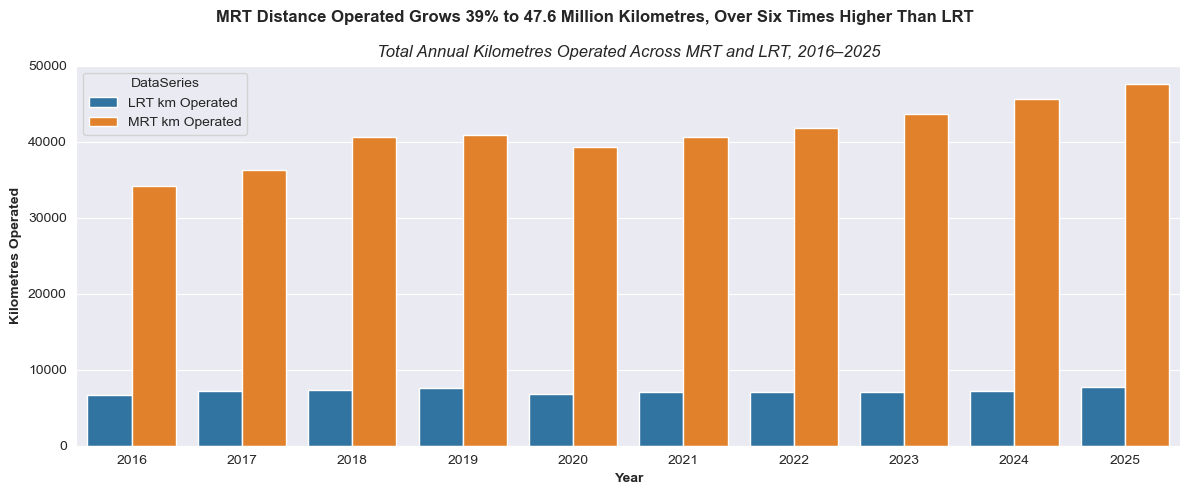

In [7]:
sns.set_style("darkgrid")
plt.figure(figsize = (12, 5))
sns.barplot(data = df_long, hue = "DataSeries", x = "Year", y = "Value")
plt.title("Total Annual Kilometres Operated Across MRT and LRT, 2016–2025", style = "italic")
plt.suptitle("MRT Distance Operated Grows 39% to 47.6 Million Kilometres, Over Six Times Higher Than LRT", fontweight = "bold")
plt.xlabel("Year", fontweight = "bold")
plt.ylabel("Kilometres Operated", fontweight = "bold")
plt.tight_layout()
plt.show()

#### BQ3: What is the percentage share of average daily ridership contributed by MRT, LRT, and Public Buses in 2025?

In [8]:
avg_daily_ridership = public_transport_ops_ridership_annual_df[(public_transport_ops_ridership_annual_df['DataSeries'].str.strip() == 'Average Daily Ridership - MRT') | 
                                                               (public_transport_ops_ridership_annual_df['DataSeries'].str.strip() == 'Average Daily Ridership - LRT') | 
                                                               (public_transport_ops_ridership_annual_df['DataSeries'].str.strip() == 'Average Daily Ridership - Public Bus')]
avg_daily_ridership_2025 = avg_daily_ridership.loc[:, "DataSeries": "2025"]
avg_daily_ridership_2025['DataSeries'] = avg_daily_ridership_2025['DataSeries'].replace({'Average Daily Ridership - MRT': 'MRT', 
                                                                           'Average Daily Ridership - LRT': 'LRT', 
                                                                           'Average Daily Ridership - Public Bus': 'Public Bus'})
avg_daily_ridership_2025

,DataSeries,2025
5,MRT,3490
6,LRT,209
7,Public Bus,3841


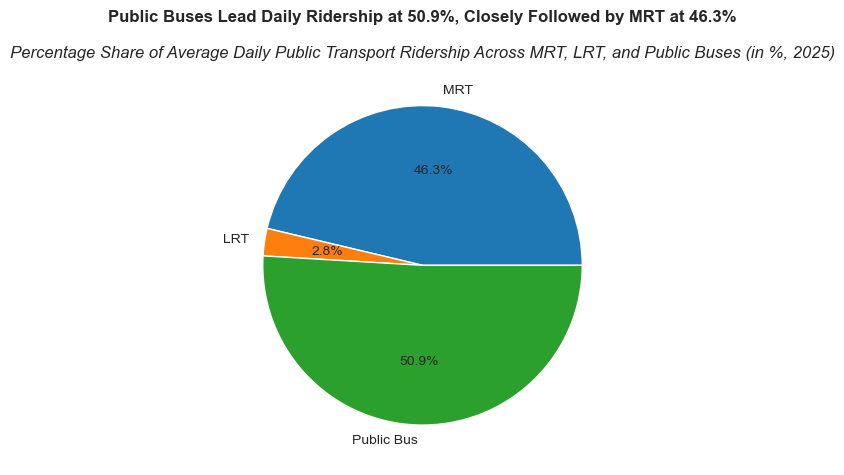

In [9]:
sns.set_style("darkgrid")
plt.pie(avg_daily_ridership_2025['2025'], 
        labels = avg_daily_ridership_2025['DataSeries'], 
        autopct = "%1.1f%%", 
        startangle = 0)
plt.title("Percentage Share of Average Daily Public Transport Ridership Across MRT, LRT, and Public Buses (in %, 2025)", style = 'italic')
plt.suptitle("Public Buses Lead Daily Ridership at 50.9%, Closely Followed by MRT at 46.3%", fontweight = 'bold')
plt.tight_layout()
plt.show()

#### BQ4: What is the frequency distribution of annual average daily ridership levels for Public Buses across all recorded years?

In [24]:
avg_daily_riderships_public_buses = public_transport_ops_ridership_annual_df[public_transport_ops_ridership_annual_df['DataSeries'].str.strip() == "Average Daily Ridership - Public Bus"]
avg_daily_riderships_public_buses

,DataSeries,2025,2024,2023,2022,2021,2020,2019,2018,2017,...,1999,1998,1997,1996,1995,1994,1993,1992,1991,1990
7,Average Daily Ridership - Public Bus,3841,3837.0,3747.0,3461.0,3008.0,2878.0,4099.0,4037,3952,...,3213,3121,3116,3118,3009,na,na,na,na,na


In [28]:
avg_daily_riderships_public_buses_values = avg_daily_riderships_public_buses.loc[7, "2025": "1995"].values.astype("float64")
avg_daily_riderships_public_buses_values

array([3841., 3837., 3747., 3461., 3008., 2878., 4099., 4037., 3952.,
       3939., 3891., 3751., 3601., 3481., 3385., 3199., 3047., 3087.,
       2932., 2833., 2779., 2805., 2992., 3197., 3281., 3251., 3213.,
       3121., 3116., 3118., 3009.])

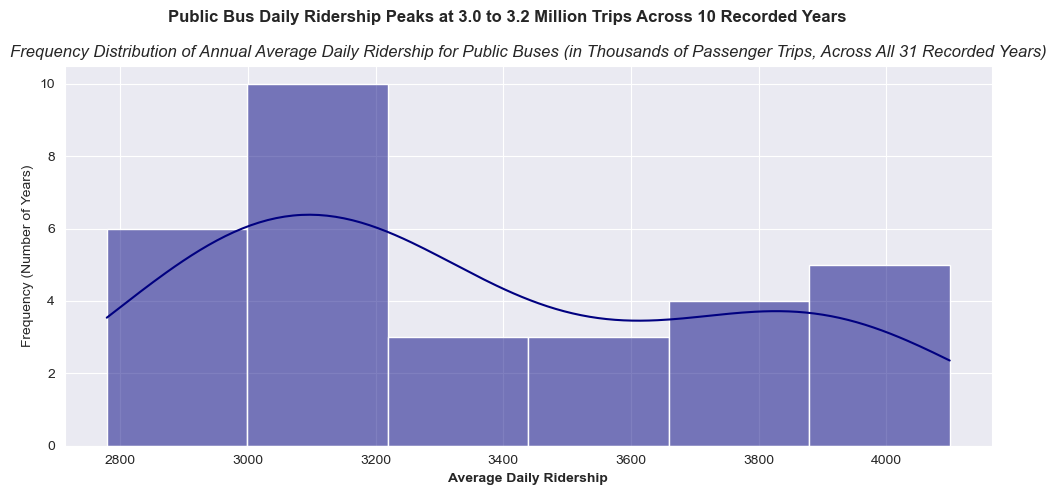

In [ ]:
sns.set_style("darkgrid")
plt.figure(figsize = (10, 5))
sns.histplot(data = avg_daily_riderships_public_buses_values, kde = True, color = "navy")
plt.title("Frequency Distribution of Annual Average Daily Ridership for Public Buses (in Thousands of Passenger Trips, Across All 31 Recorded Years)", style = "italic")
plt.suptitle("Public Bus Daily Ridership Peaks at 3.0 to 3.2 Million Trips Across 10 Recorded Years", fontweight = "bold")
plt.xlabel("Average Daily Ridership", fontweight = "bold")
plt.ylabel("Frequency (Number of Years)", fontweight = "bold")
plt.tight_layout()
plt.show()

#### BQ5: Is there a positive correlation between Rail Length and Average Daily Ridership - MRT over the recorded years?

In [39]:
rail_length_avg_daily_ridership_mrt_df = pd.DataFrame({"Rail Length": public_transport_ops_ridership_annual_df.loc[0, "2025": "1995"].astype("float64"), 
                                                       "Avg Daily Ridership - MRT": public_transport_ops_ridership_annual_df.loc[5, "2025": "1995"].astype("float64")})
rail_length_avg_daily_ridership_mrt_df

,Rail Length,Avg Daily Ridership - MRT
2025,271.3,3490.0
2024,271.3,3412.0
2023,258.5,3243.0
2022,258.5,2745.0
2021,245.3,2100.0
2020,232.3,2023.0
2019,228.1,3384.0
2018,228.1,3302.0
2017,228.1,3122.0
2016,199.6,3095.0


In [41]:
rail_length_avg_daily_ridership_mrt_df.corr()

,Rail Length,Avg Daily Ridership - MRT
Rail Length,1.000000,0.917487
Avg Daily Ridership - MRT,0.917487,1.000000


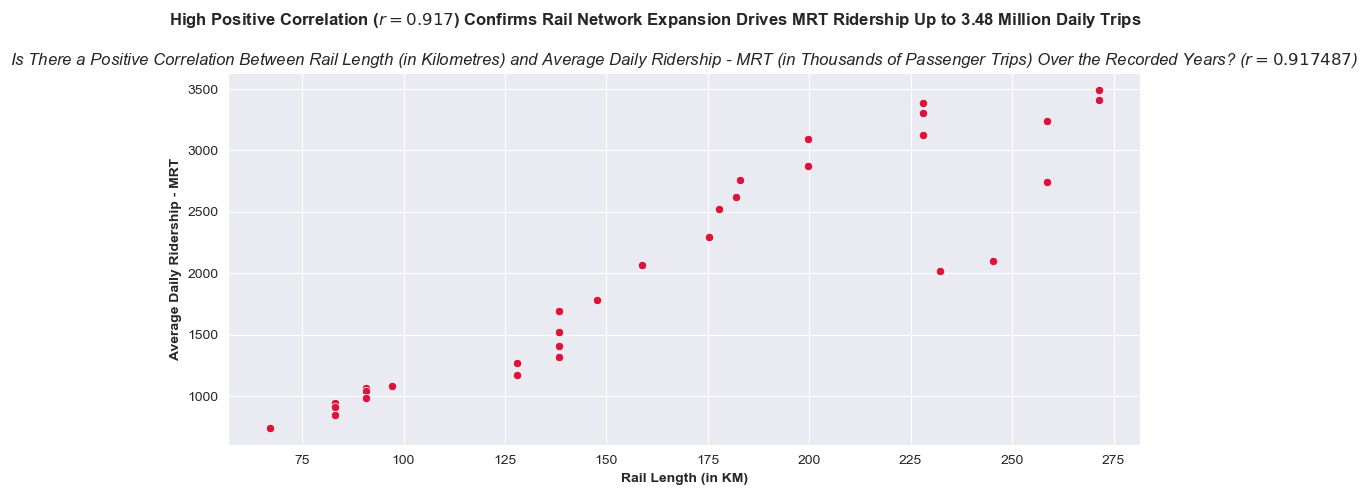

In [49]:
sns.set_style("darkgrid")
plt.figure(figsize = (10, 5))
sns.scatterplot(data = rail_length_avg_daily_ridership_mrt_df, x = "Rail Length", y = "Avg Daily Ridership - MRT", color = "crimson")
plt.title("Is There a Positive Correlation Between Rail Length (in Kilometres) and Average Daily Ridership - MRT (in Thousands of Passenger Trips) Over the Recorded Years? ($r = 0.917487$)", style= "italic")
plt.suptitle("High Positive Correlation ($r = 0.917$) Confirms Rail Network Expansion Drives MRT Ridership Up to 3.48 Million Daily Trips", fontweight = "bold")
plt.xlabel("Rail Length (in KM)", fontweight = "bold")
plt.ylabel("Average Daily Ridership - MRT", fontweight = "bold")
plt.tight_layout()
plt.show()